# Лабораторная работа 3. Деревья решений. Часть 1

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

По данным о пассажирах Титаника решить задачу классификации с помощью дерева решений: по
характеристикам пассажиров найти у выживших два наиболее важных признака из трёх, заданных
вариантом.

| Пункт задания | Вариант 20 |
|---|---|
| Данные | пассажиры Титаника, набор `heptapod/titanic` с Kaggle |
| Признаки | `Pclass`, `Parch`, `Fare` |
| Модель | дерево решений `DecisionTreeClassifier` |
| Ответ | два признака с наибольшей важностью |
| Образец кода | пособие «Теория и практика машинного обучения», пункт «Работа с деревьями решений», стр. 188–191, листинг 24 |

## Ход работы

1. Загрузить данные о пассажирах и подготовить выборку.
2. Обучить дерево решений на трёх признаках варианта.
3. Определить два важнейших признака и проверить, зависит ли ответ от глубины дерева.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

from mllab import RANDOM_STATE
from mllab.datasets import load_titanic
from mllab.reporting import make_table


FEATURES = ["Pclass", "Parch", "Fare"]
TARGET = "Survived"
TEXTBOOK_STATE = 241  # random_state из листинга 24 пособия
LABELED = 891  # у пассажиров с большим PassengerId исход неизвестен
FOLDS = 10

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные о пассажирах

Признаки варианта:

- `Pclass` — класс билета от 1 до 3, первый класс самый дорогой;
- `Parch` — сколько родителей и детей пассажира было на борту;
- `Fare` — цена билета.

Набор данных уже предобработан: 

- пол закодирован числом;
- пропуски в возрасте и цене билета заполнены;
- целевой столбец переименован в `Survived`;
- убраны пустые столбцы.

In [2]:
titanic = load_titanic()
labeled = titanic.index <= LABELED

make_table(
    {
        "пассажиров в наборе": len(titanic),
        **{
            f"пропусков в {column}": int(np.isnan(titanic[column]).sum())
            for column in [*FEATURES, TARGET]
        },
        "доля выживших, все пассажиры": round(titanic[TARGET].mean(), 3),
        f"доля выживших, PassengerId ≤ {LABELED}": round(titanic.loc[labeled, TARGET].mean(), 3),
        f"выживших среди PassengerId > {LABELED}": int(titanic.loc[~labeled, TARGET].sum()),
    }
)

,значение
,
пассажиров в наборе,1309
пропусков в Pclass,0
пропусков в Parch,0
пропусков в Fare,0
пропусков в Survived,0
"доля выживших, все пассажиры",0.261
"доля выживших, PassengerId ≤ 891",0.384
выживших среди PassengerId > 891,0


Пропусков в признаках и цели нет. Доля выживших по всему набору равна 0.261, а среди первых
891 пассажира — 0.384. Набор собран из двух частей: обучающей
(`PassengerId` от 1 до 891) и тестовой (от 892 до 1309). Исход пассажиров тестовой части не публикуется, и в этом файле он заполнен нулями: среди 418 пассажиров нет ни
одного выжившего. Если обучать дерево на всём наборе, оно будет считать погибшими людей, про
которых на самом деле ничего не известно. Поэтому дальше для обучения используются только 891 пассажир с
известным исходом.

In [3]:
passengers = titanic.loc[labeled, [*FEATURES, TARGET]]
X_titanic = passengers[FEATURES]
y_titanic = passengers[TARGET]

make_table(
    {
        "пассажиров": len(passengers),
        "выжили / погибли": f"{y_titanic.sum()} / {(1 - y_titanic).sum()}",
        **{f"различных значений {column}": X_titanic[column].nunique() for column in FEATURES},
    }
)

,значение
,
пассажиров,891
выжили / погибли,342 / 549
различных значений Pclass,3
различных значений Parch,7
различных значений Fare,248


Посмотрим, как доля выживших зависит от каждого признака по отдельности.
Значения `Parch` от 3 и выше объединены в одну группу, т. к. таких пассажиров всего 15. `Fare`
разбит на пять групп с равным числом пассажиров, над столбцами подписан размер группы.

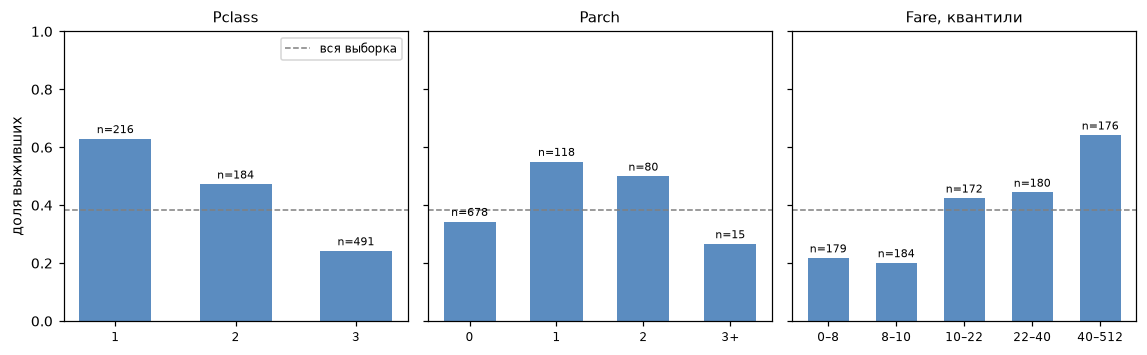

In [4]:
fare_bins = pd.qcut(passengers["Fare"], 5)
fare_labels = [
    f"{max(interval.left, 0):.0f}–{interval.right:.0f}" for interval in fare_bins.cat.categories
]
groups = {
    "Pclass": passengers["Pclass"],
    "Parch": passengers["Parch"].clip(upper=3).astype(str).replace("3", "3+"),
    "Fare, квантили": fare_bins.cat.rename_categories(fare_labels),
}

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3), sharey=True)
for ax, (title, group) in zip(axes, groups.items(), strict=True):
    stats = y_titanic.groupby(group, observed=True).agg(["mean", "size"])
    bars = ax.bar(stats.index.astype(str), stats["mean"], color="#5b8cc0", width=0.6)
    ax.bar_label(bars, labels=[f"n={size}" for size in stats["size"]], fontsize=7, padding=2)
    ax.axhline(y_titanic.mean(), color="grey", linestyle="--", linewidth=1, label="вся выборка")
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylim(0, 1)

axes[0].set_ylabel("доля выживших")
axes[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

`Pclass` и `Fare` связаны с выживанием сильно и в одну сторону. В первом классе выжили 63%
пассажиров, в третьем — 24%. Среди двух групп с самыми дешёвыми билетами выжил примерно каждый
пятый, среди самых дорогих — 64%. Эти признаки частично связаны между собой (чем выше класс, тем дороже билет).

У `Parch` зависимость слабее и меняет направление. Пассажиры с одним или двумя родственниками
выживали чаще одиночек (55% и 50% против 34%), а с тремя и более — реже, но таких пассажиров
слишком мало, чтобы доверять этой доле. Кроме того, 678 пассажиров из 891 путешествовали без
родителей и детей, и для них признак одинаков.

## 2. Дерево решений

Дерево решений задаёт пассажиру последовательность вопросов вида «значение признака $x_j$ не
больше порога $b$?». Каждый вопрос делит пассажиров на две группы, и в каждой группе задаётся
следующий вопрос. Вершина, на которой вопросы заканчиваются, называется листом. В каждый лист
попадает часть пассажиров из обучающей выборки, и дерево предсказывает тот исход, который среди
них встречается чаще.

Дерево строится сверху вниз, начиная с корня, в котором находятся все пассажиры. В каждой вершине
перебираются все признаки и все пороги. Пороги берутся посередине между соседними значениями
признака: у `Pclass` значения 1, 2 и 3, поэтому порогов два: 1.5 и 2.5. Из всех вариантов
выбирается вопрос, после которого группы получаются чище, т. е. в каждой из них сильнее преобладает
один исход.

Чтобы сравнивать деления между собой, чистоту группы нужно выразить числом. По умолчанию
`DecisionTreeClassifier` использует для этого индекс Джини:

$$G = 1 - p_0^2 - p_1^2 ,$$

где $p_0$ и $p_1$ — доли погибших и выживших в группе, а сам индекс равен вероятности ошибиться, если
взять из группы случайного пассажира и назвать его исход наугад: «погиб» с вероятностью $p_0$, «выжил» с
вероятностью $p_1$. Если все пассажиры группы принадлежат одному классу, то ошибиться нельзя и $G = 0$. Если
классы поровну, то $G = 0.5$ — это самая перемешанная группа. В группе, где погибли 9 из 10: $G = 1 - 0.9^2 - 0.1^2 = 0.18$.

Деление оценивается тем, насколько оно уменьшило индекс. У двух новых групп индексы свои, и их
усредняют с весами по размеру групп:

$$\Delta G = G - \frac{N_L}{N}\, G_L - \frac{N_R}{N}\, G_R ,$$

где $N$ — число пассажиров в вершине, $N_L$ и $N_R$ — в левой и правой группах. Веса нужны, чтобы
маленькая чистая группа не перевешивала большую. Пусть в вершине 10 пассажиров, из них выжили 5,
$G = 0.5$:

- вопрос А делит их на 5 и 5, в первой группе выжили 4, во второй 1: $G_L = G_R = 0.32$ и
  $\Delta G = 0.5 - 0.5 \cdot 0.32 - 0.5 \cdot 0.32 = 0.18$;
- вопрос Б отделяет двух выживших, а среди остальных 8 выжили 3: $G_L = 0$, $G_R = 0.469$ и
  $\Delta G = 0.5 - 0.2 \cdot 0 - 0.8 \cdot 0.469 = 0.125$.

Вопрос Б дал полностью чистую группу, но в ней всего двое, а остальные восемь перемешаны почти так
же, как до деления. Дерево выберет вопрос А.

Выбрав деление с наибольшим $\Delta G$, дерево повторяет то же самое в каждой из двух групп. С
параметрами по умолчанию глубина не ограничена: дерево растёт, пока в каждом листе не останутся
пассажиры с одним исходом или с одинаковыми значениями всех признаков, которых никаким порогом не
разделить.

Важность признака показывает, насколько деления по этому признаку в сумме очистили выборку. Для
каждого деления его $\Delta G$ умножается на долю всех пассажиров, которая дошла до этой вершины, и
результаты складываются по признакам. Из-за этого множителя деление в корне весит больше, чем
деление маленькой группы внизу дерева. Если в выборке 891 пассажир:

- деление корня с $\Delta G = 0.05$ добавляет к важности своего признака $1 \cdot 0.05 = 0.05$;
- идеальное деление группы из 10 пассажиров, где выжила половина, имеет $\Delta G = 0.5$, но
  добавляет только $\frac{10}{891} \cdot 0.5 \approx 0.006$.

Мелких делений внизу дерева много, и вместе они могут набрать заметную долю важности. В конце
важности всех признаков делятся на их сумму, чтобы в сумме получилась 1. Эти значения хранятся в
поле `feature_importances_`.

Дерево обучено с параметрами листинга 24: `random_state=241`, остальные по умолчанию. Признаки в
каждой вершине перебираются в случайном порядке, и если два деления дают одинаковое $\Delta G$,
выбор между ними зависит от `random_state`.

In [5]:
classifier = DecisionTreeClassifier(random_state=TEXTBOOK_STATE).fit(X_titanic, y_titanic)
importances = pd.Series(classifier.feature_importances_, index=FEATURES).sort_values(
    ascending=False
)

make_table(
    {
        **{f"важность {name}": round(value, 3) for name, value in importances.items()},
        "глубина дерева": classifier.get_depth(),
        "листьев": classifier.get_n_leaves(),
        "accuracy на обучающей выборке": round(classifier.score(X_titanic, y_titanic), 3),
    }
)

,значение
,
важность Fare,0.688
важность Pclass,0.22
важность Parch,0.092
глубина дерева,15
листьев,191
accuracy на обучающей выборке,0.823


Дерево выросло до глубины 15 и 191 листа и верно классифицирует 82.3% пассажиров обучающей
выборки. На диаграмме ниже представлены только первые три уровня. В каждой вершине указаны вопрос, индекс Джини
(`gini`), число пассажиров (`samples`), сколько из них погибли и выжили (`value`) и класс
большинства. Чем насыщеннее цвет, тем сильнее преобладает этот класс.

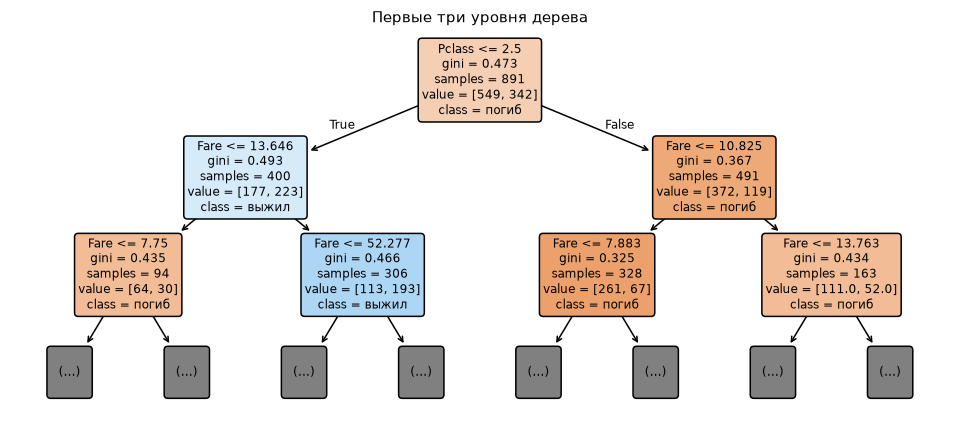

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
plot_tree(
    classifier,
    max_depth=2,
    feature_names=FEATURES,
    class_names=["погиб", "выжил"],
    filled=True,
    impurity=True,
    proportion=False,
    rounded=True,
    fontsize=8,
    ax=ax,
)
ax.set_title("Первые три уровня дерева")
plt.show()

В корне 891 пассажир, из них выжили 342, и $G = 1 - 0.616^2 - 0.384^2 = 0.473$. Лучшим первым
делением оказался вопрос `Pclass <= 2.5`, т. е. «первый или второй класс?»:

- в первом и втором классе 400 пассажиров, выжили 223, $G_L = 0.493$;
- в третьем классе 491 пассажир, выжили 119, $G_R = 0.367$.

$$\Delta G = 0.473 - \frac{400}{891} \cdot 0.493 - \frac{491}{891} \cdot 0.367 = 0.049 .$$

Левая группа вышла даже менее чистой, чем корень, но правая стала заметно чище, и в сумме индекс
уменьшился. Все шесть делений ниже корня на схеме идут по `Fare`.

## 3. Два важнейших признака

Ответ составляют два признака с наибольшей важностью.

In [7]:
answer = importances.index[:2].tolist()
make_table(
    {
        f"{place}. {name}": round(importances[name], 3)
        for place, name in enumerate(answer, start=1)
    },
    column="важность",
)

,важность
,
1. Fare,0.688
2. Pclass,0.22


Два наиболее важных признака — `Fare` (0.688) и `Pclass` (0.220). У `Parch` важность 0.092. Это
согласуется с графиками раздела 1: доля выживших сильнее всего меняется по классу и цене билета.

Для проверки дерево обучено ещё раз на всех 1309 пассажирах, вместе с нулевыми метками тестовой
части.

In [8]:
on_all = DecisionTreeClassifier(random_state=TEXTBOOK_STATE)
on_all.fit(titanic[FEATURES], titanic[TARGET])
pd.DataFrame(
    {
        f"PassengerId ≤ {LABELED}": importances,
        "все пассажиры": pd.Series(on_all.feature_importances_, index=FEATURES),
    }
).loc[importances.index].round(3)

,PassengerId ≤ 891,все пассажиры
Fare,0.688,0.726
Pclass,0.220,0.137
Parch,0.092,0.138


На всём наборе `Pclass` и `Parch` получают почти одинаковую важность, 0.137 и 0.138, и второе
место в ответе решает третий знак после запятой. Отбор пассажиров с известным исходом на ответ
влияет.

### Важность `Fare`

Важность `Fare` втрое больше, чем у `Pclass`, хотя на графиках оба признака связаны с выживанием
одинаково сильно, а корень делится по `Pclass`. Скорее всего, дело в числе порогов: у `Pclass` их
два, у `Parch` — шесть, у `Fare` — 247. Когда пороги по классу исчерпаны, дерево делит группы дальше в
основном по цене билета, вплоть до отдельных пассажиров. Каждое такое деление добавляет свою долю $\Delta G$ к важности `Fare`.

Такие деления подгоняют дерево под конкретных пассажиров, общей закономерности за ними нет.
Проверить это можно только на пассажирах, которых дерево не видело при обучении. Поэтому ниже
деревья разной глубины сравниваются кросс-валидацией: выборка делится на 10 частей, дерево 10 раз
обучается на девяти частях и проверяется на оставшейся, accuracy усредняется.

In [9]:
folds = StratifiedKFold(FOLDS, shuffle=True, random_state=RANDOM_STATE)
rows = []
for depth in (2, 3, 4, 6, 8, None):
    model = DecisionTreeClassifier(max_depth=depth, random_state=TEXTBOOK_STATE)
    model.fit(X_titanic, y_titanic)
    rows.append(
        {
            "глубина": depth or "без ограничения",
            "листьев": model.get_n_leaves(),
            **dict(zip(FEATURES, model.feature_importances_.round(3), strict=True)),
            "accuracy обучение": round(model.score(X_titanic, y_titanic), 3),
            "accuracy CV": round(cross_val_score(model, X_titanic, y_titanic, cv=folds).mean(), 3),
        }
    )

pd.DataFrame(rows).set_index("глубина")

,листьев,Pclass,Parch,Fare,accuracy обучение,accuracy CV
глубина,,,,,,
2,4,0.722,0.000,0.278,0.706,0.683
3,8,0.541,0.000,0.459,0.718,0.714
4,14,0.455,0.081,0.464,0.740,0.730
6,36,0.350,0.128,0.522,0.759,0.738
8,70,0.284,0.128,0.588,0.781,0.732
без ограничения,191,0.220,0.092,0.688,0.823,0.696


Чем глубже дерево, тем больше важность `Fare`: 0.278 при глубине 2 и 0.688 без ограничения.
Accuracy на обучении растёт вместе с глубиной до 0.823, а на кросс-валидации лучший результат
0.738 при глубине 6, после чего она падает до 0.696. Дерево без ограничения запоминает отдельных
пассажиров, т. е. переобучается, и большая часть лишних делений приходится на `Fare`.

Пара важнейших признаков от глубины не зависит: при любой глубине это `Pclass` и `Fare`, а
`Parch` последний. Порядок внутри пары зависит: у деревьев глубины 2 и 3 впереди `Pclass`, у
более глубоких — `Fare`. 

## Выводы

1. Два важнейших признака для выживания пассажиров — `Fare`
   (0.688) и `Pclass` (0.220), у `Parch` — 0.092.
2. Пара `Fare` и `Pclass` не меняется при любой глубине дерева. Порядок внутри неё зависит от
   глубины: у деревьев глубины 2 и 3 впереди `Pclass`.
3. Важность признака в дереве зависит от числа его значений. У `Fare` 248 значений, и дерево без
   ограничения глубины делит по нему вплоть до отдельных пассажиров: accuracy 0.823 на обучении
   и 0.696 на кросс-валидации. Часть важности `Fare` — следствие переобучения.

## Контрольные вопросы

**1. Расскажите подробнее об используемой вами модели дерева решений.**

В scikit-learn реализован алгоритм CART. Дерево бинарное: в каждой вершине одно условие
$x_j \le b$ по одному признаку. `DecisionTreeClassifier` в каждой вершине перебирает все признаки
и пороги и выбирает деление, сильнее всего уменьшающее индекс Джини. Лист возвращает класс,
которого среди попавших в него обучающих объектов больше.

Без ограничений дерево растёт, пока листья не станут однородными, и легко переобучается. Рост
ограничивают параметры `max_depth` и `min_samples_leaf`. Масштабирования признаков дерево не
требует, т. к. сравнивает значения только с порогами, а его решения можно прочитать как набор
правил. Важность признака — суммарное уменьшение индекса Джини по всем делениям на этом
признаке. Она завышает признаки с большим числом значений, что и произошло с `Fare`.

**2. Какая типовая задача машинного обучения решается в обеих частях лабораторной?**

В обеих частях решается задача обучения с учителем: по объектам с известным ответом
восстановить зависимость ответа от признаков. В первой части предсказывается класс (выжил или
нет) — это классификация, а ответ на задание дают важности признаков обученного дерева. Во второй
части предсказывается сумма сделки — регрессия.

**3. Какими ещё моделями можно решить поставленные задачи?**

Классификацию выживших можно решить логистической регрессией, методом k ближайших соседей,
методом опорных векторов, ансамблями деревьев: случайным лесом и градиентным бустингом.
Для любой модели важность можно оценить перестановкой: перемешать значения
признака на проверочной выборке и измерить, насколько упало качество.